# Módulo 7 — Cointegração

## Seção 2 — Definição formal de cointegração, combinações estacionárias e equilíbrio de longo prazo

**Estado editorial:** versão didática para revisão científica. **Pré-requisitos:** Seção 1 deste módulo; variância, covariância e $I(d)$; noções de regressão e ADF. **Escopo:** definição e exemplos de cointegração **entre séries $I(1)$**, teste de Engle–Granger apenas como introdução operacional, e uma primeira derivação de correção de erros; Johansen e VECM ficam para seções seguintes.

**Controle das fontes.** O plano prioritário determina o estudo formal de cointegração após a regressão espúria. O mapeamento das videoaulas classifica o assunto como **não encontrado** e sugere Hamilton (1994, caps. 19–20) e Enders (2014) para consulta posterior. A formalização abaixo é uma **complementação matemática original baseada na formulação clássica de Engle e Granger (1987)**, não transcrição de páginas verificadas; não se atribui ao PDF de Morettin e Toloi um tratamento específico não confirmado.

### Objetivos de aprendizagem

Você deverá (i) definir integração e cointegração sem confundi-las; (ii) interpretar o vetor cointegrante; (iii) construir um par $I(1)$ com resíduo $I(0)$; (iv) contrastá-lo com dois passeios independentes; (v) executar `statsmodels.tsa.stattools.coint` e reconhecer a hipótese nula; (vi) deduzir a ideia de correção de erros em um exemplo controlado; (vii) explicar as restrições de inferência e interpretação.

### 1. Motivação: duas séries podem caminhar, mas sua diferença permanecer limitada

Duas séries podem apresentar tendência estocástica — não oscilar em torno de um nível fixo — e ainda assim preservar uma **relação linear estável**. Pense em preços de bens estreitamente relacionados ou duas medidas de um mesmo sistema: cada um pode flutuar persistentemente, mas um desvio relativo grande pode desencadear forças de ajuste.

**Cointegração não significa que as séries tenham valores próximos.** Significa que uma **combinação linear não trivial** de seus níveis tem ordem de integração menor que a de cada série, sob hipóteses precisas. A interpretação de 'equilíbrio' é uma motivação econômica ou física; a propriedade matemática sozinha não prova causalidade, arbitragem nem mecanismo de ajuste.

### 2. Relembrando integração $I(d)$

Uma série $X_t$ é tratada como $I(1)$ quando não é estacionária em nível, mas sua primeira diferença $\Delta X_t=X_t-X_{t-1}$ é $I(0)$, dentro da classe de processos e condições de regularidade apropriadas. $I(0)$ será usado aqui para séries fracamente estacionárias de memória curta nos nossos exemplos; a definição econométrica pode exigir condições adicionais, como comportamento de longo prazo não degenerado.

Para o passeio aleatório

$$
X_t=X_{t-1}+\varepsilon_t,\qquad \varepsilon_t\stackrel{\mathrm{i.i.d.}}{\sim}(0,\sigma_\varepsilon^2),
$$

sua primeira diferença recupera $\varepsilon_t$. A notação $\stackrel{\mathrm{i.i.d.}}{\sim}(0,\sigma^2)$ abrevia **independência e momentos**, não especifica uma distribuição normal. Quando usamos normalidade nas simulações, ela será declarada separadamente.

### 3. Definição formal: da combinação linear à ordem de integração

Considere um vetor $\mathbf Z_t=(Z_{1t},\ldots,Z_{pt})^\top$ cujas componentes são $I(d)$, com $d>0$. Dizemos que há **cointegração de ordem $(d,b)$** quando existe um vetor não nulo $\boldsymbol\beta\in\mathbb R^p$ tal que

$$
\boxed{\boldsymbol\beta^\top\mathbf Z_t\sim I(d-b),\qquad b>0.}
$$

Para o caso principal deste módulo, $d=b=1$:

$$
\boxed{\mathbf Z_t\text{ tem componentes }I(1),\quad
\exists\boldsymbol\beta\ne\mathbf0:\ \boldsymbol\beta^\top\mathbf Z_t\sim I(0).}
$$

- $p$ é o número de séries; $t$ é o instante.
- $\boldsymbol\beta$ é o **vetor cointegrante**; seus coeficientes formam uma combinação linear dos níveis.
- 'Não nulo' evita a combinação trivial de zeros, que seria estacionária sem informar nada.
- Na definição básica, os componentes devem ter a mesma ordem de integração. Para séries de ordens mistas ou integrações fracionárias, é necessária teoria adicional.

A expressão $\sim I(0)$ refere-se ao **processo** de combinação, não ao fato de a sequência observada 'parecer horizontal'. Se houver intercepto ou tendência determinística na relação, sua inclusão ou exclusão deve ser explicitada no modelo e no procedimento de teste.

### 4. Uma construção exata de duas séries cointegradas

Considere, com $\beta\ne0$ e $|\phi|<1$:

$$
X_t=X_{t-1}+\varepsilon_t,
\qquad
u_t=\phi u_{t-1}+\eta_t,
\qquad
Y_t=\alpha+\beta X_t+u_t.
$$

Suponha inovações $\varepsilon_t$ e $\eta_t$ de média zero, variâncias finitas positivas, independentes entre si e ao longo do tempo, e $u_t$ na sua solução causal estacionária.

**Passo 1 — $X_t$ é $I(1)$.** Sua primeira diferença é $\varepsilon_t$, que tem média e variância constantes. Sua variância em nível cresce com $t$ para um início fixo.

**Passo 2 — $u_t$ é $I(0)$.** O AR(1) causal com $|\phi|<1$ é fracamente estacionário e possui

$$
E[u_t]=0,\qquad \operatorname{Var}(u_t)=\frac{\sigma_\eta^2}{1-\phi^2},\qquad
\gamma_u(h)=\frac{\sigma_\eta^2}{1-\phi^2}\phi^{|h|}.
$$

**Passo 3 — $Y_t$ herda a tendência estocástica.** Pela construção, sua primeira diferença é

$$
\Delta Y_t=\beta\Delta X_t+\Delta u_t
=\beta\varepsilon_t+(\phi-1)u_{t-1}+\eta_t.
$$

Sob independência entre $X_t$ e $u_t$, $Y_t$ não é estacionário em nível: para início fixo de $X_t$, $\operatorname{Var}(Y_t)=\beta^2t\sigma_\varepsilon^2+\operatorname{Var}(u_t)$. Entretanto $\Delta Y_t$ é estacionário de segunda ordem, pois soma processos estacionários apropriados. Assim, $Y_t$ é $I(1)$ neste exemplo.

**Passo 4 — encontrar a combinação.** Rearranjando a equação de $Y_t$:

$$
\boxed{Y_t-\beta X_t-\alpha=u_t\sim I(0).}
$$

Ou, com $\mathbf Z_t=(Y_t,X_t)^\top$,

$$
\boldsymbol\beta_c=\begin{pmatrix}1\\-\beta\end{pmatrix},\qquad
\boldsymbol\beta_c^\top\mathbf Z_t=\alpha+u_t.
$$

Como adicionar a constante $\alpha$ preserva estacionariedade, o vetor é cointegrante. **A letra $\beta_c$ indica o vetor cointegrante, diferente do escalar $\beta$ que multiplica $X_t$.**

### 5. Exemplo numérico completamente interpretado

Escolha $\alpha=3$, $\beta=1{,}5$, $\phi=0{,}4$, $\sigma_\varepsilon^2=1$ e $\sigma_\eta^2=0{,}36$.

A variância estacionária do desvio de equilíbrio é

$$
\operatorname{Var}(u_t)=\frac{0{,}36}{1-0{,}4^2}=
\frac{0{,}36}{0{,}84}\approx0{,}42857.
$$

A autocorrelação desse desvio na primeira defasagem é $\rho_u(1)=0{,}4$. O vínculo de longo prazo é

$$
\boxed{Y_t\approx3+1{,}5X_t},\quad
\underbrace{Y_t-3-1{,}5X_t}_{\text{desvio de equilíbrio}}=u_t.
$$

A igualdade com $\approx$ descreve a parte sistemática; a igualdade com $u_t$ é **exata na construção**. Se em um instante $X_t=10$ e $u_t=-0{,}6$, então $Y_t=3+1{,}5(10)-0{,}6=17{,}4$. O valor de equilíbrio condicional à posição de $X_t$ seria $18$; o desvio vale $-0{,}6$.

**Atenção à normalização:** multiplicar o vetor $\boldsymbol\beta_c$ por uma constante diferente de zero produz a mesma relação de cointegração. Para apresentar resultados, fixamos o coeficiente de $Y_t$ em 1; isso é uma convenção, não um achado causal.

### 6. Contraste: duas séries $I(1)$ independentes não são cointegradas neste modelo

Se $X_t=\sum_{j=1}^{t}\varepsilon_j$ e $Y_t=\sum_{j=1}^{t}\eta_j$, com inovações independentes de variância positiva, então, para quaisquer constantes $a,b$ não ambas nulas,

$$
\operatorname{Var}(aX_t+bY_t)=t(a^2\sigma_\varepsilon^2+b^2\sigma_\eta^2).
$$

A variância cresce com $t$, pois o fator em parênteses é estritamente positivo. Portanto, **nenhuma combinação linear não trivial** desses dois passeios é fracamente estacionária. Isso demonstra, para a construção específica, ausência de cointegração.

Comparar essa demonstração com a Seção 1 explica a diferença: uma reta estimada nos dados não produz, por si só, uma combinação estacionária na população.

### 7. Python — processo cointegrado e processo não cointegrado

Usaremos NumPy, Matplotlib e Statsmodels. Para a simulação, as inovações serão normais e independentes. O descarte inicial (*burn-in*) reduz a influência de iniciar $u_t$ em zero; os resultados em finita amostra continuam aleatórios.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import coint

rng = np.random.default_rng(20261121)
n, burn = 500, 200
alpha, beta, phi = 3.0, 1.5, 0.4
x = np.cumsum(rng.normal(size=n))
eta = rng.normal(scale=0.6, size=n + burn)
u_ext = np.zeros(n + burn)
for t in range(1, len(u_ext)):
    u_ext[t] = phi * u_ext[t-1] + eta[t]
u = u_ext[burn:]
y_coint = alpha + beta*x + u

y_ind = np.cumsum(rng.normal(size=n))  # outro passeio, independente

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
axes[0, 0].plot(x, label='X, I(1)')
axes[0, 0].plot(y_coint, label='Y cointegrado, I(1)')
axes[0, 0].legend()
axes[0, 0].set_title('Dois níveis que compartilham uma tendência')
axes[0, 1].plot(y_coint-alpha-beta*x)
axes[0, 1].set_title('Desvio de equilíbrio = u (estacionário)')
axes[1, 0].plot(x, label='X, I(1)')
axes[1, 0].plot(y_ind, label='Y independente, I(1)')
axes[1, 0].legend()
axes[1, 0].set_title('Dois passeios independentes')
axes[1, 1].plot(y_ind-x)
axes[1, 1].set_title('Diferença de níveis sem cointegração')
for ax in axes.ravel():
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

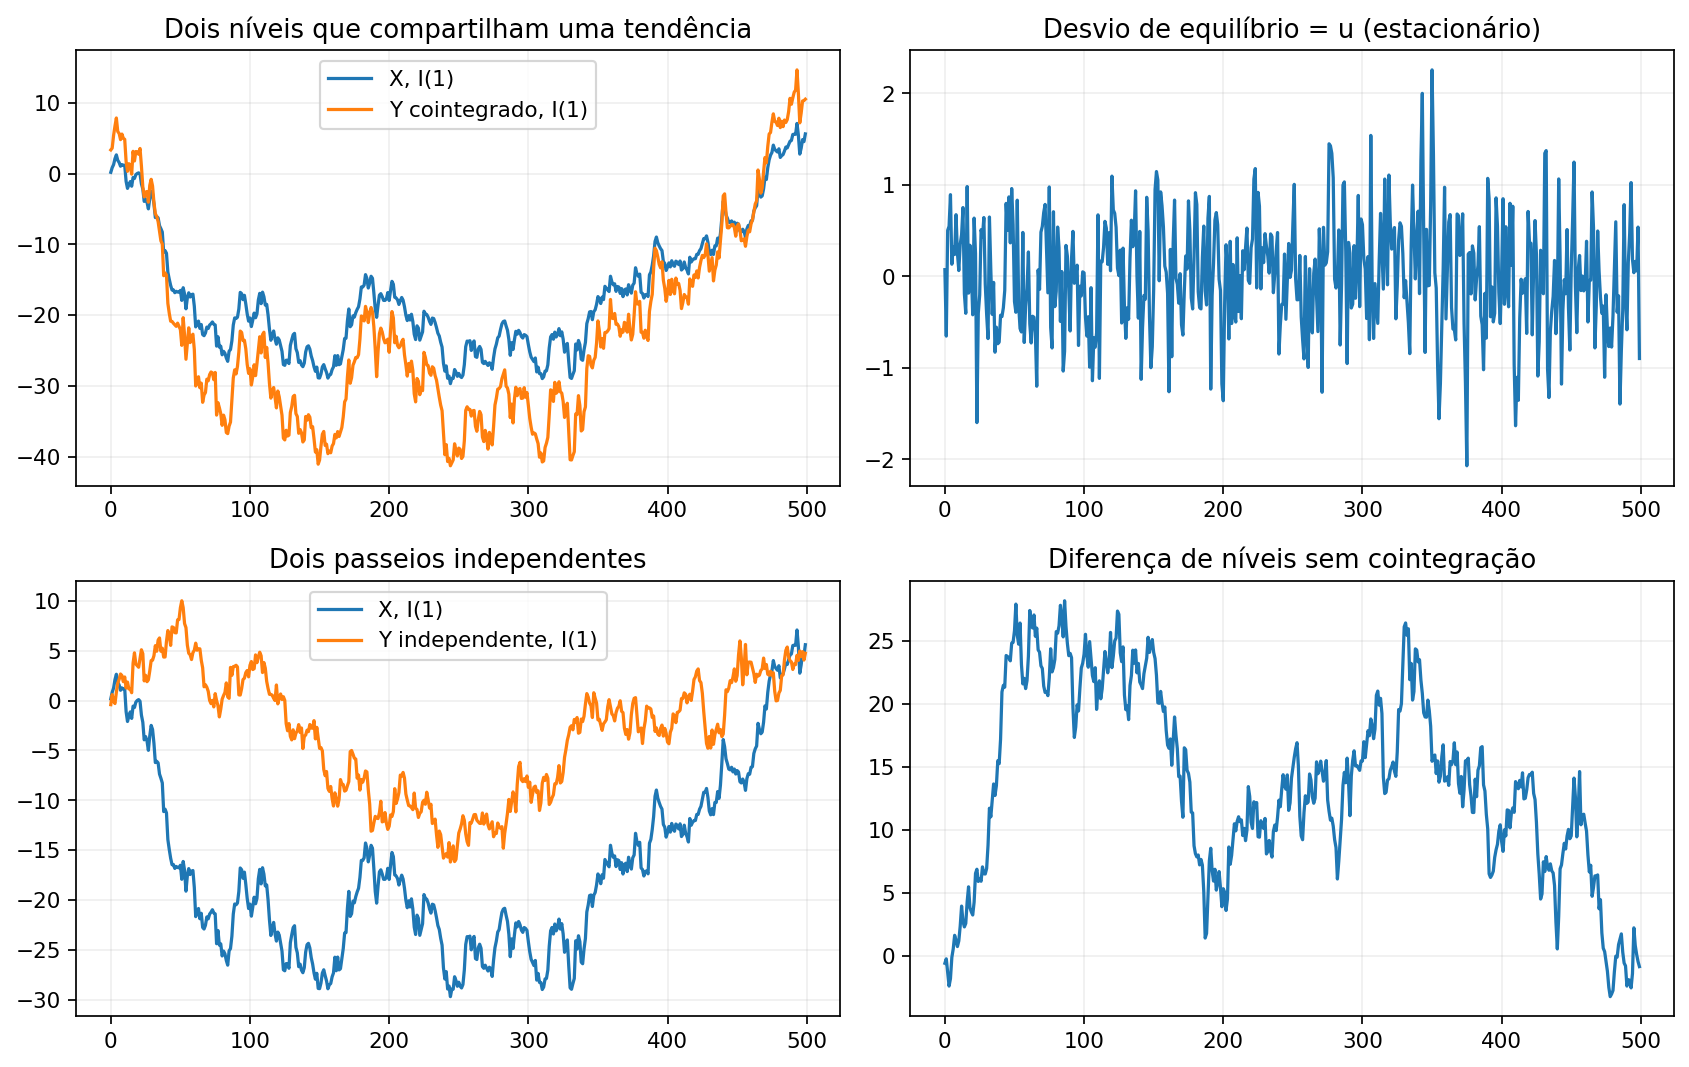

*Figura 7.3 — Acima: níveis integrados com uma combinação estacionária. Abaixo: níveis de passeios independentes e uma diferença que ainda é integrada. A figura é ilustrativa; o status de integração foi estabelecido pelas equações e hipóteses do exemplo.*

### 8. Introdução operacional ao teste residual de Engle–Granger

Uma abordagem clássica de duas etapas é: (1) estimar uma relação de níveis $Y_t=\alpha+\beta X_t+u_t$; (2) investigar se o resíduo estimado é estacionário. A presença de intercepto e/ou tendência determinística deve ser especificada conforme a hipótese científica.

**Hipóteses da versão usual de teste:**

$$
H_0:\text{não há cointegração},\qquad
H_1:\text{há cointegração na especificação adotada}.
$$

O ponto crítico é que o resíduo **foi produzido por uma regressão estimada**. Mesmo quando a segunda etapa utiliza uma regressão semelhante ao ADF, seus valores críticos e $p$-valores **não** são os do ADF convencional aplicado a uma série observada sem etapa prévia de estimação.

No Statsmodels, `coint(y, x, trend='c', autolag='aic')` implementa um teste de Engle–Granger com constante na relação de cointegração; retorna estatística, $p$-valor aproximado e valores críticos apropriados à configuração. Escolhas de tendência e de defasagens afetam a interpretação.

In [ ]:
from statsmodels.tsa.stattools import coint

# Reutilize x, y_coint e y_ind da célula anterior.
for nome, yy in [('Par cointegrado', y_coint),
                 ('Passeios independentes', y_ind)]:
    estatistica, p_valor, criticos = coint(yy, x, trend='c', autolag='aic')
    print(f'{nome}: t={estatistica:.3f}, p={p_valor:.4f}')
    print('Críticos [1%, 5%, 10%]:', np.round(criticos, 3))

Os resultados são **evidência estatística**, não provas absolutas. Uma simulação pode ocasionalmente levar a erro de decisão. Antes do teste, é importante investigar se as duas séries são compatíveis com integração de ordem 1, lembrando a potência limitada de ADF/KPSS e o impacto de quebras estruturais. Uma eventual rejeição de $H_0$ não prova causalidade.

### 9. Primeira ponte para correção de erros (ECM)

No exemplo controlado, $Y_t=\alpha+\beta X_t+u_t$ e $u_t=\phi u_{t-1}+\eta_t$. Tome diferenças:

$$
\Delta Y_t=\beta\Delta X_t+u_t-u_{t-1}.
$$

Substitua a dinâmica estacionária do desvio:

$$
u_t-u_{t-1}=(\phi-1)u_{t-1}+\eta_t.
$$

Como $u_{t-1}=Y_{t-1}-\alpha-\beta X_{t-1}$, chegamos a

$$
\boxed{\Delta Y_t=\beta\Delta X_t+
\underbrace{(\phi-1)}_{\lambda_{\mathrm{ajuste}}}
\underbrace{(Y_{t-1}-\alpha-\beta X_{t-1})}_{\text{erro de equilíbrio anterior}}
+\eta_t.}
$$

Para $\phi=0{,}4$, $\lambda_{\mathrm{ajuste}}=-0{,}6$. Se o desvio anterior for $+2$, sua contribuição **condicional, mantidos os demais termos** é $-1{,}2$ à variação atual de $Y$. O sinal negativo representa retorno parcial ao equilíbrio neste modelo particular.

**Importantíssimo:** $\lambda_{\mathrm{ajuste}}$ é um coeficiente de velocidade de ajuste, **não** o $\lambda$ da transformação Box–Cox do Módulo 5. O cálculo aqui é uma identidade decorrente das equações escolhidas; não basta estimar um coeficiente negativo em dados reais para provar existência de mecanismo causal. Os procedimentos de estimação de ECM e sistemas VECM serão desenvolvidos nas seções seguintes.

### 10. Interpretação, hipóteses e limites

- **Ordem de integração:** a definição desta seção pressupõe séries compatíveis com $I(1)$; misturar $I(0)$ e $I(1)$ sem adaptar a teoria compromete a conclusão.
- **Vetor cointegrante:** em duas variáveis costuma ser único até normalização quando a estrutura é não degenerada; com mais variáveis podem existir múltiplas relações e um posto de cointegração.
- **Parâmetros estáveis:** quebras, mudanças de regime, amostras curtas e sazonalidade mal tratada podem alterar testes e estimativas.
- **Exogeneidade e direção:** uma regressão de cointegração não estabelece que uma variável cause a outra ou que só uma delas se ajuste.
- **Precisão preditiva:** testar cointegração não demonstra que qualquer modelo resultante preveja melhor; usar validação cronológica e diagnóstico residual.
- **Cointegração versus correlação:** correlação amostral alta não é condição necessária nem suficiente. A propriedade central é a **ordem de integração da combinação linear**.
- **Demonstração e teste:** nossa construção simulada estabelece cointegração pela definição; o teste Engle–Granger apenas busca evidências dela a partir de uma trajetória.

### 11. Exercícios graduais

**Conceito.** Explique em palavras por que o fato de $X_t$ e $Y_t$ serem ambos $I(1)$ não implica cointegração.

**Álgebra.** Para $Y_t=5+2X_t+u_t$, com $u_t$ AR(1) estacionário de parâmetro $0{,}3$, identifique um vetor cointegrante e calcule a variância de $u_t$ se $\operatorname{Var}(\eta_t)=1$.

**Prova.** Demonstre que dois passeios aleatórios independentes de variâncias positivas não admitem uma combinação linear não trivial de variância constante.

**ECM.** Deduzir, sem consultar a fórmula final, a equação de correção de erros da Seção 9 a partir do modelo em nível e da recorrência de $u_t$.

**Programação guiada.** Antes de codificar, faça pseudocódigo com: geração de $X_t$; geração de $u_t$; construção de $Y_t$; cálculo da combinação $Y_t-\alpha-\beta X_t$; comparação com um segundo passeio independente. Em seguida varie $\phi$ entre $0{,}1$ e $0{,}9$ sem alterar a regra $|\phi|<1$ e interprete a velocidade de retorno.

**Investigação.** Aplique `coint` a amostras de vários tamanhos e sementes, registrando não rejeições equivocadas e rejeições equivocadas. **Não** confunda frequência empírica de erros com probabilidade exata em qualquer situação.

**Orientação selecionada:** no exercício algébrico, $\boldsymbol\beta_c=(1,-2)^\top$; a relação $Y_t-2X_t=5+u_t$ é $I(0)$; $\operatorname{Var}(u_t)=1/(1-0{,}3^2)=1/0{,}91$.

### 12. Síntese, continuidade e referências

**Integração** descreve a ordem de diferenciação necessária para obter uma dinâmica estacionária sob hipóteses apropriadas; **cointegração** descreve uma combinação de níveis integrados cujo desvio de equilíbrio tem ordem menor. Esse vínculo permite investigar relações de longo prazo sem cometer a inferência convencional da regressão espúria. A presença de erro estacionário também sugere uma representação de ajuste de curto prazo, que será formalizada em ECM/VECM.

**Próximas seções previstas:** desenvolvimento matemático do procedimento Engle–Granger (estimação e valores críticos); modelos ECM, sistemas VAR/VECM e metodologia de Johansen.

**Fontes do projeto efetivamente consultadas:** `PLANO_MODULOS_PRIORITARIOS.md`, Módulo 7; `mapeamento-conteudos-series-temporais.md`, §6.1 e tabela de lacunas. **Referências acadêmicas clássicas para conferência posterior:** ENGLE, R. F.; GRANGER, C. W. J. *Co-integration and error correction: Representation, estimation, and testing*. Econometrica, 1987; HAMILTON, J. D. *Time Series Analysis*, 1994, caps. 19–20; ENDERS, W. *Applied Econometric Time Series*, 2014. **A construção, dedução do ECM particular, simulações e exercícios são complementações didáticas originais**, sem atribuir afirmações a páginas não verificadas.